In [1]:
import nafusion_utils.daq as daq
import matplotlib.pyplot as plt
import nafusion_utils as na
import numpy as np
import nafusion_utils.polyspectrum as ps
import matplotlib.colors as mc
na.set_style()
%matplotlib widget

[]

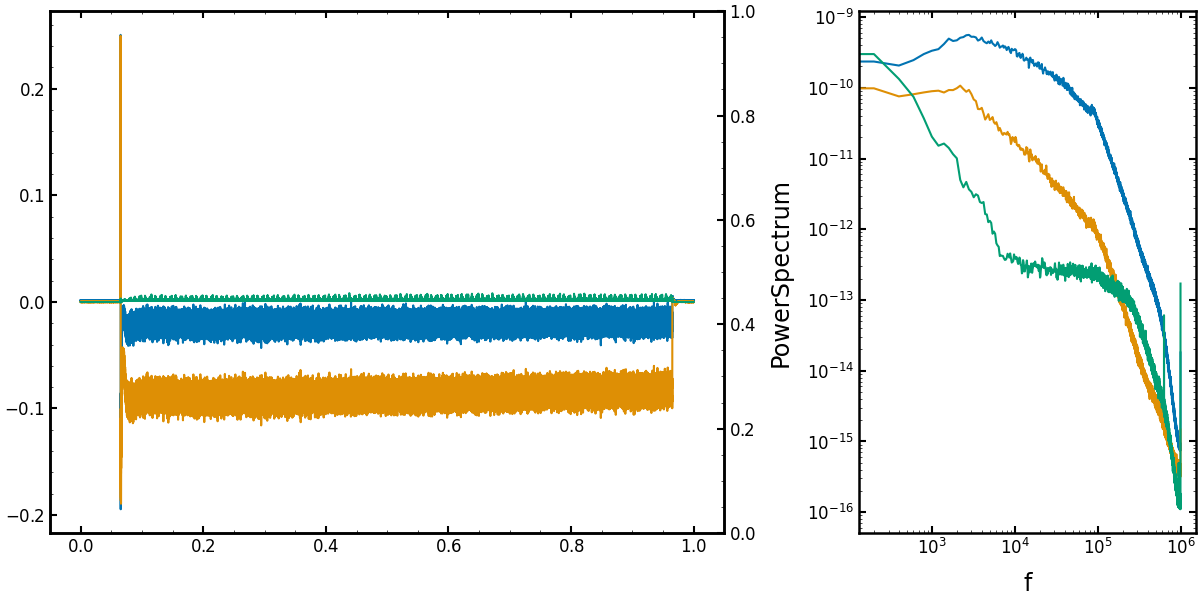

In [ ]:
# path = "/Users/kawachi/Library/CloudStorage/SynologyDrive-mercury/Research/experiment/exp_data/PANTA/2609"
path = "/Volumes/data/expdata"  # <<===
# /Volumes/data/expdata/DL950/019000
shot = 19408

zshot = str(shot).zfill(6)
DLNAME = path + f"/DL950/019000/{zshot}/{zshot}_DL950_0000.wvf"


def read_we(_zshot, tower, station, ch):
    return daq.read_wvf(path + f"/WE7000/019000/{_zshot}/{tower}_{station}_{str(ch).zfill(2)}.wvf", digitizer="WE7000")


WEPATH = lambda tower, station, ch: path + f"/WE7000/019000/{zshot}/{tower}_{station}_{str(ch).zfill(2)}.wvf"
dl = daq.read_wvf(DLNAME, digitizer="DL950")
vf1 = dl.CH1_1
vf2 = dl.CH2_1
Ey = vf1 - vf2  # ほんとは揺動成分だけ抜き出してEytildeにしたほうがいい
vct = dl.CH1_2
# I = read_we(2, 1, 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 6), width_ratios=[2, 1])
axes[0].plot(vf1.time, vf1, label="vf1")
axes[0].plot(vf2.time, vf2, label="vf2")
axes[0].plot(vct.time, vct, label="vct")
axx = axes[0].twinx()
# axx.plot(I.time, I, color="k", label="I1")

# ps.PSD(vf1.sel(time=slice(0.5, 0.8)).data, fs=2e6).plot(ax=axes[1], label="vf1")
ps.PSD(vf2.sel(time=slice(0.1, 0.8)).data, fs=2e6).plot(ax=axes[1], label="vf2")
ps.PSD(Ey.sel(time=slice(0.5, 0.8)).data, fs=2e6).plot(ax=axes[1], label="Ey")
ps.PSD(vct.sel(time=slice(0.5, 0.8)).data, fs=2e6).plot(ax=axes[1], label="vfctr")
axes[1].loglog()

# 64ch


In [69]:
s, e = 0.1, 0.2
shot = 19404
sig_64ch = []
for i in range(1, 4):
    for j in range(1, 17):
        da = read_we(str(shot).zfill(6), 2, i, j).sel(time=slice(s, e))
        sig_64ch.append(da / da.mean() - 1)
for j in range(1, 17):
    da = read_we(str(shot).zfill(6), 3, 1, j).sel(time=slice(s, e))
    sig_64ch.append(da / da.mean() - 1)
sig_64ch = np.array(sig_64ch)

[]

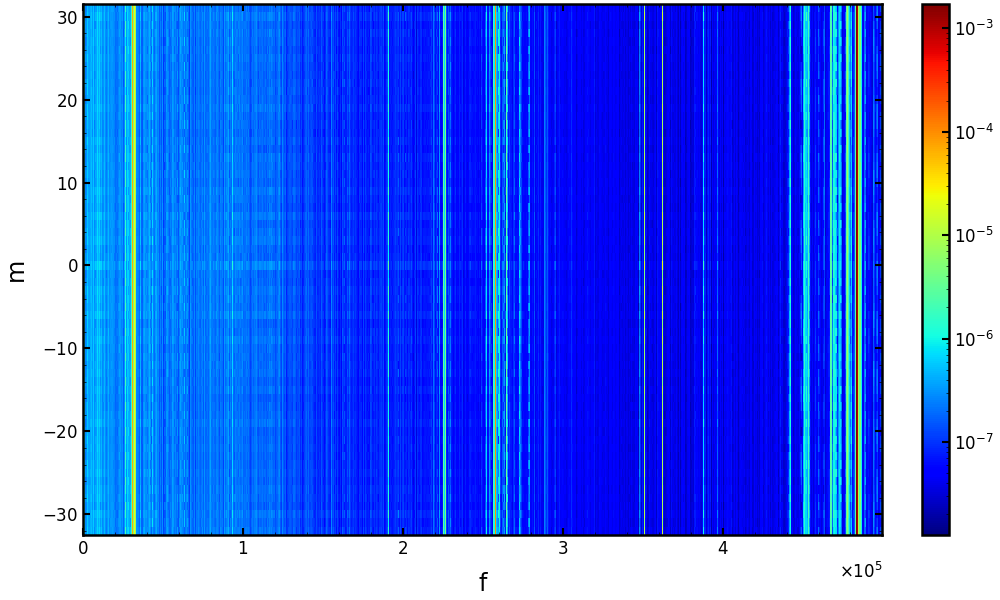

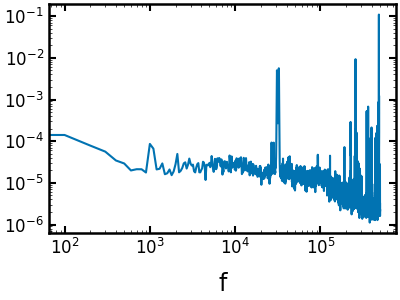

In [70]:
plt.figure(figsize=(10, 6))
# plt.pcolormesh(sig_64ch, cmap="jet")
psd_2d = ps.PSD_2d(sig_64ch, mode="64ch")
psd_2d.plot(norm=mc.LogNorm(), cmap="jet")
plt.xlim(0)
plt.figure()
psd_2d.sum("m").plot()
plt.loglog()
# ps.PSD_2d(sig_64ch[1::2], mode="32ch").plot(norm=mc.LogNorm(), cmap="jet")
# for i in range(64)[20:50]:
#     ps.PSD(sig_64ch[i]).plot()
# plt.loglog()

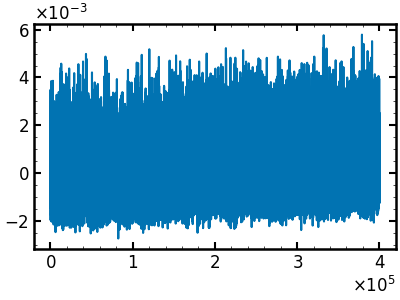

In [39]:
# path = "/Users/kawachi/Library/CloudStorage/SynologyDrive-mercury/Research/experiment/exp_data/PANTA/2609"
path = "/Volumes/data/expdata"  # <<===
# /Volumes/data/expdata/DL950/019000


plt.figure()
for i in [19380]:
    shot = i
    zshot = str(shot).zfill(6)
    DLNAME = path + f"/DL950/019000/{zshot}/{zshot}_DL950_0000.wvf"
    dl = daq.read_wvf(DLNAME, digitizer="DL950").sel(time=slice(0.3, 0.5))
    Vf1 = dl.CH1_1 - dl.CH1_1.mean()
    Vf2 = dl.CH2_1 - dl.CH2_1.mean()
Ey = Vf1 - Vf2

plt.plot(Ey)
#     ps.PSD((Vf1 - Vf2).data, fs=2e6).plot(label=f"shot={shot}")
# # ps.PSD(dl.CH1_1.sel(time=slice(0, 0.05)).data, fs=2e6).plot(label=f"shot={shot}")

# # ps.CSD(dl.CH1_1.sel(time=slice(0.4, 0.5)).data, dl.CH1_2.sel(time=slice(0.4, 0.5)).data, fs=2e6).squared_coherence.plot()
# plt.loglog()
# # plt.xscale("log")

[]

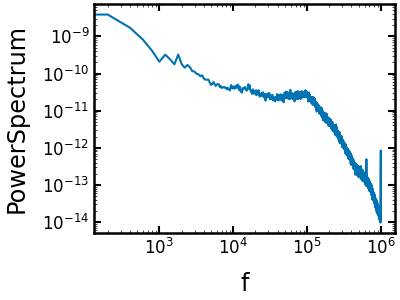

In [24]:
plt.figure()
ps.PSD(dl.CH1_2.sel(time=slice(0.3, 0.5)).data, fs=2e6).plot(label="sig_64ch[0]")
plt.loglog()

[]

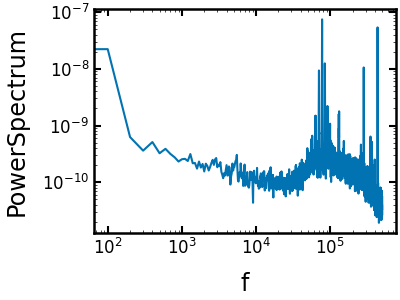

In [25]:
plt.figure()
ps.PSD(sig_64ch[0]).plot()

plt.loglog()